# CellRank trajectory inference: RNA velocity + moscot, alone and combined

**Cell set.** The kernel-weighting study runs on the 68,166 **devbrain** cells. RNA velocity
needs spliced/unspliced counts, which exist only for these (Brooks has `norm_counts`/
`raw_counts` only), and CellRank requires every kernel in a combination to be defined over
the same cells. The graph is built on `X_pca_harmony_joint` - the Harmony embedding from the
joint devbrain+Brooks run - so root-cell selection still benefits from the Brooks bridge even
though Brooks cells are not themselves in the kernel. A moscot-only run on the full 9-stage
joint object is in `cellrank_joint_moscot.ipynb`.

**Kernels**
- `VelocityKernel` - directional, from RNA velocity (velocyto spliced/unspliced -> scVelo)
- `RealTimeKernel` - directional, from moscot optimal transport between consecutive stages
- `ConnectivityKernel` - undirected, a symmetric smoother; never used alone for direction

**Runs.** Each kernel alone, then five weightings, all with identical estimator settings so
the comparison is like-for-like. The question each one answers: does it find an e7.0 root,
and do the terminal states agree?

In [1]:
import os
import pickle

import numpy as np
import pandas as pd
import scanpy as sc
import scvelo as scv
import cellrank as cr
import matplotlib.pyplot as plt

print("cellrank", cr.__version__, "| scvelo", scv.__version__, "| scanpy", sc.__version__)
sc.settings.verbosity = 2
scv.settings.verbosity = 2
sc.settings.set_figure_params(dpi=100, dpi_save=200, frameon=False, figsize=(5, 5))

# --- compatibility shim -------------------------------------------------
# scanpy 1.11.5 calls .getnnz() on the kNN distance matrix, but scipy >= 1.16
# hands back a csr_*array* (sparse arrays dropped getnnz), so sc.pp.neighbors
# raises AttributeError. Restore the method rather than pinning scipy, which
# would risk the numpy-2 ABI that petsc4py in this env is built against.
import scipy.sparse as _sp

if not hasattr(_sp.csr_array, "getnnz"):
    def _getnnz(self, axis=None):
        if axis is None:
            return int(self.nnz)
        if axis == 1:
            return np.diff(self.indptr)
        return np.bincount(self.indices, minlength=self.shape[1])
    for _cls in (_sp.csr_array, _sp.csc_array):
        _cls.getnnz = _getnnz
    print("patched sparse-array getnnz for scanpy/scipy compatibility")
# ------------------------------------------------------------------------


def as_sparse_matrices(adata):
    """Force obsp/layers to scipy sparse *matrices*.

    anndata >= 0.12 hands back csr_*arrays*, but scvelo 0.3.4 still uses
    matrix-only APIs (.A1, .getnnz), so it crashes on them. Convert at the
    source instead of patching each call site. Re-run after anything that
    rebuilds these (subsetting, copying).
    """
    from scipy.sparse import csr_matrix, issparse, spmatrix
    for store in (adata.obsp, adata.layers):
        for k in list(store.keys()):
            v = store[k]
            if issparse(v) and not isinstance(v, spmatrix):
                store[k] = csr_matrix(v)
    return adata

cellrank 2.0.7 | scvelo 0.3.4 | scanpy 1.11.5
patched sparse-array getnnz for scanpy/scipy compatibility


In [2]:
base = "/project/imoskowitz/yubin/Trajectory_inference/"
fig_cr = base + "output_fig/07_cellrank/"
res_dir = base + "data/cellrank/"
for d in (fig_cr, res_dir):
    os.makedirs(d, exist_ok=True)
sc.settings.figdir = fig_cr
scv.settings.figdir = fig_cr

BASIS = "X_umap_joint"          # joint Harmony UMAP, for plotting
REP = "X_pca_harmony_joint"     # joint Harmony PCA, for graphs
N_STATES = 12                   # macrostates, fixed across runs for comparability
N_TERMINAL = 4                  # terminal states to take, see predict_terminal_states

In [3]:
adata = sc.read_h5ad(base + "data/devbrain_velocity.h5ad")
print(adata)
print("\nlayers:", list(adata.layers.keys()))
print("spliced total  :", f"{int(adata.layers['spliced'].sum()):,}")
print("unspliced total:", f"{int(adata.layers['unspliced'].sum()):,}")
print("\ncells per stage:")
print(adata.obs["age"].value_counts().sort_index().to_string())

AnnData object with n_obs × n_vars = 68166 × 21743
    obs: 'barcode', 'sample', 'run', 'age', 'tissue', 'total_counts', 'n_genes', 'is_cell', 'age_num', 'n_genes_by_counts', 'total_counts_mt', 'pct_counts_mt', 'total_counts_ribo', 'pct_counts_ribo', 'leiden', 'chip', 'leiden_harmony', 'velocyto_covered', 'leiden_joint', 'stage_num'
    var: 'gene_ids', 'gene_symbol', 'mt', 'ribo', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells', 'highly_variable', 'means', 'dispersions', 'dispersions_norm', 'highly_variable_nbatches', 'highly_variable_intersection'
    uns: 'age_colors', 'harmony', 'hvg', 'leiden', 'leiden_colors', 'leiden_harmony', 'log1p', 'neighbors', 'pca', 'sample_colors', 'source', 'tissue_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_pca_harmony_joint', 'X_umap', 'X_umap_harmony', 'X_umap_joint', 'X_umap_unintegrated'
    varm: 'PCs'
    layers: 'ambiguous', 'counts', 'spliced', 'unspliced'
    obsp: 'connectivities', 'distances',

## Is the devbrain-only graph connected on the joint embedding?

The joint run connected e7.0 through *Brooks* cells. Removing them may re-isolate it. This is
checked up front, because it bounds what the velocity kernel can say about the early lineage.

In [4]:
sc.pp.neighbors(adata, n_neighbors=30, use_rep=REP)
as_sparse_matrices(adata)

from scipy.sparse.csgraph import connected_components
n_comp, labels = connected_components(adata.obsp["connectivities"], directed=False)
sizes = pd.Series(labels).value_counts()
print(f"{n_comp} connected components; largest = {100*sizes.iloc[0]/adata.n_obs:.1f}% of cells")
adata.obs["component"] = labels

A = (adata.obsp["connectivities"] > 0).astype(np.float32)
cats = list(adata.obs["age"].cat.categories)
onehot = np.zeros((adata.n_obs, len(cats)), dtype=np.float32)
onehot[np.arange(adata.n_obs), adata.obs["age"].cat.codes.values] = 1
frac = A @ onehot
frac = frac / np.maximum(frac.sum(1, keepdims=True), 1)
mix = pd.DataFrame([frac[(adata.obs["age"] == c).values].mean(0) for c in cats],
                   index=cats, columns=cats)
print("\nage mixing on the devbrain-only graph built from the joint embedding:")
print((100 * mix).round(1).to_string())

computing neighbors


    finished (0:08:59)


1 connected components; largest = 100.0% of cells

age mixing on the devbrain-only graph built from the joint embedding:
       e7.0       e8.0       e8.5       e9.0      e10.0
e7.0   98.0   1.900000   0.000000   0.000000   0.100000
e8.0    3.7  86.099998   6.900000   2.400000   0.800000
e8.5    0.1  14.700000  66.099998  12.800000   6.300000
e9.0    0.0   1.000000   2.300000  55.599998  41.099998
e10.0   0.0   0.200000   0.500000  21.200001  78.000000


## scVelo: moments and velocity

In [5]:
HH_GENES = ["Gli1", "Hhip", "Smo", "Shh", "Ptch1"]

# scvelo 0.3.4 dropped n_top_genes/log/subset_highly_variable from
# filter_and_normalize - it now only filters and normalizes, so the log and HVG
# steps come from scanpy. X is reset to raw counts first: it arrives
# log-normalized from the processed object, and scvelo expects counts.
adata.X = adata.layers["counts"].copy()
scv.pp.filter_and_normalize(adata, min_shared_counts=20, retain_genes=HH_GENES)
sc.pp.log1p(adata)
sc.pp.highly_variable_genes(adata, n_top_genes=2000)

# retain_genes keeps the Hh genes through the count filter; this keeps them
# through the HVG subset too (Gli1 and Shh are too sparse to be HVGs)
keep = np.asarray(adata.var["highly_variable"]) | np.asarray(adata.var_names.isin(HH_GENES))
adata = adata[:, keep].copy()
print(f"after prep: {adata.shape}")
print("Hh genes retained:", [g for g in HH_GENES if g in adata.var_names])

as_sparse_matrices(adata)          # the gene subset above rebuilt layers/obsp
scv.pp.moments(adata, n_pcs=None, n_neighbors=None)

Filtered out 10035 genes that are detected 20 counts (shared).


Normalized count data: X, spliced, unspliced.


extracting highly variable genes


    finished (0:00:01)


after prep: (68166, 2002)
Hh genes retained: ['Gli1', 'Hhip', 'Smo', 'Shh', 'Ptch1']
computing moments based on connectivities


    finished (0:00:07)


In [6]:
# scvelo 0.3.4's stochastic mode hits a numpy>=2 error in leastsq_generalized
# (assigning a size-1 array into a scalar slot). Patched locally in this env:
#   envs/cellrank_traj/.../scvelo/tools/optimization.py  (.orig backup alongside)
# The dynamical model would take hours on 68k cells and is only worth it if
# these velocities look coherent first.
as_sparse_matrices(adata)
scv.tl.velocity(adata, mode="stochastic")
scv.tl.velocity_graph(adata, n_jobs=int(os.environ.get("SLURM_CPUS_PER_TASK", 8)))
print("velocity genes:", int(adata.var["velocity_genes"].sum()))

computing velocities


    finished (0:00:26)


computing velocity graph (using 16/48 cores)
or disable the progress bar using `show_progress_bar=False`.


    finished (0:01:16)
velocity genes: 1366


In [7]:
scv.pl.velocity_embedding_stream(
    adata, basis=BASIS.replace("X_", ""), color="age", legend_loc="right margin",
    title="RNA velocity stream, joint Harmony UMAP", save="velocity_stream_age.png",
    show=False,
)
scv.tl.velocity_confidence(adata)
print(adata.obs[["velocity_length", "velocity_confidence"]].describe().round(2).to_string())

computing velocity embedding


    finished (0:00:12)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_velocity_stream_age.png


       velocity_length  velocity_confidence
count         68166.00             68166.00
mean             10.18                 0.90
std              10.75                 0.08
min               2.48                 0.00
25%               5.66                 0.87
50%               7.52                 0.92
75%              10.72                 0.96
max             151.56                 1.00


## moscot: optimal transport between consecutive stages

In [8]:
from moscot.problems.time import TemporalProblem

tp = TemporalProblem(adata)
tp = tp.prepare(time_key="stage_num", joint_attr={"attr": "obsm", "key": REP})
print(tp)

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/jaxopt/__init__.py:59: DeprecationWarning: JAXopt is no longer maintained. See https://docs.jax.dev/en/latest/ for alternatives.
  warnings.warn(


TemporalProblem[(9.0, 10.0), (8.0, 8.5), (8.5, 9.0), (7.0, 8.0)]


In [9]:
tp = tp.solve(epsilon=1e-2, tau_a=0.95, tau_b=0.95, scale_cost="mean")
for k, v in tp.solutions.items():
    print(f"  {k}: converged={v.converged}  cost={float(v.cost):.4g}")

INFO     Solving `4` problems                                                                                      


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(14781, 32136)].                                


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(6813, 3241)].                                  


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(3241, 14781)].                                 


INFO     Solving problem BirthDeathProblem[stage='prepared', shape=(11195, 6813)].                                 


  (9.0, 10.0): converged=True  cost=0.1467
  (8.0, 8.5): converged=True  cost=0.1758
  (8.5, 9.0): converged=True  cost=0.1856
  (7.0, 8.0): converged=True  cost=0.1972


## Build the three kernels

In [10]:
vk = cr.kernels.VelocityKernel(adata).compute_transition_matrix()
print(vk)

ck = cr.kernels.ConnectivityKernel(adata).compute_transition_matrix()
print(ck)

rtk = cr.kernels.RealTimeKernel.from_moscot(tp)
rtk = rtk.compute_transition_matrix(self_transitions="all", conn_weight=0.2)
print(rtk)

Computing transition matrix using `'deterministic'` model


  0%|          | 0/68166 [00:00<?, ?cell/s]

  0%|          | 1/68166 [00:06<118:15:53,  6.25s/cell]

  0%|          | 139/68166 [00:06<36:46, 30.83cell/s]  

  0%|          | 279/68166 [00:06<15:37, 72.42cell/s]

...

ConnectivityKernel[n=68166]


  0%|          | 0/4 [00:00<?, ?time pair/s]

100%|██████████| 4/4 [00:00<00:00, 34735.44time pair/s]

Using automatic `threshold=7.576540658152026e-19`


RealTimeKernel[n=68166]


## One estimator run per kernel / weighting

Identical settings everywhere: the same `n_states`, the same cluster key, the same
`X_umap_joint` for plotting. Terminal *and* initial states are predicted - the initial state
is the point of this exercise, so it is reported explicitly along with which stage it falls in.

In [11]:
KERNELS = {
    "velocity":            vk,
    "realtime_moscot":     rtk,
    "connectivity":        ck,
    "vk0.8_ck0.2":         0.8 * vk + 0.2 * ck,
    "vk0.8_rtk0.2":        0.8 * vk + 0.2 * rtk,
    "vk0.5_rtk0.5":        0.5 * vk + 0.5 * rtk,
    "vk0.2_rtk0.8":        0.2 * vk + 0.8 * rtk,
    "vk0.6_rtk0.2_ck0.2":  0.6 * vk + 0.2 * rtk + 0.2 * ck,
}
print("\n".join(f"{k:22s} {type(v).__name__}" for k, v in KERNELS.items()))

velocity               VelocityKernel
realtime_moscot        RealTimeKernel
connectivity           ConnectivityKernel
vk0.8_ck0.2            KernelAdd
vk0.8_rtk0.2           KernelAdd
vk0.5_rtk0.5           KernelAdd
vk0.2_rtk0.8           KernelAdd
vk0.6_rtk0.2_ck0.2     KernelAdd


velocity


Computing Schur decomposition


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:09)


Computing `12` macrostates


Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:02:58)


...

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:05:12)



[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 13 Broken Pipe: Likely while reading or writing to a socket
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_realtime_moscot_macrostates.png


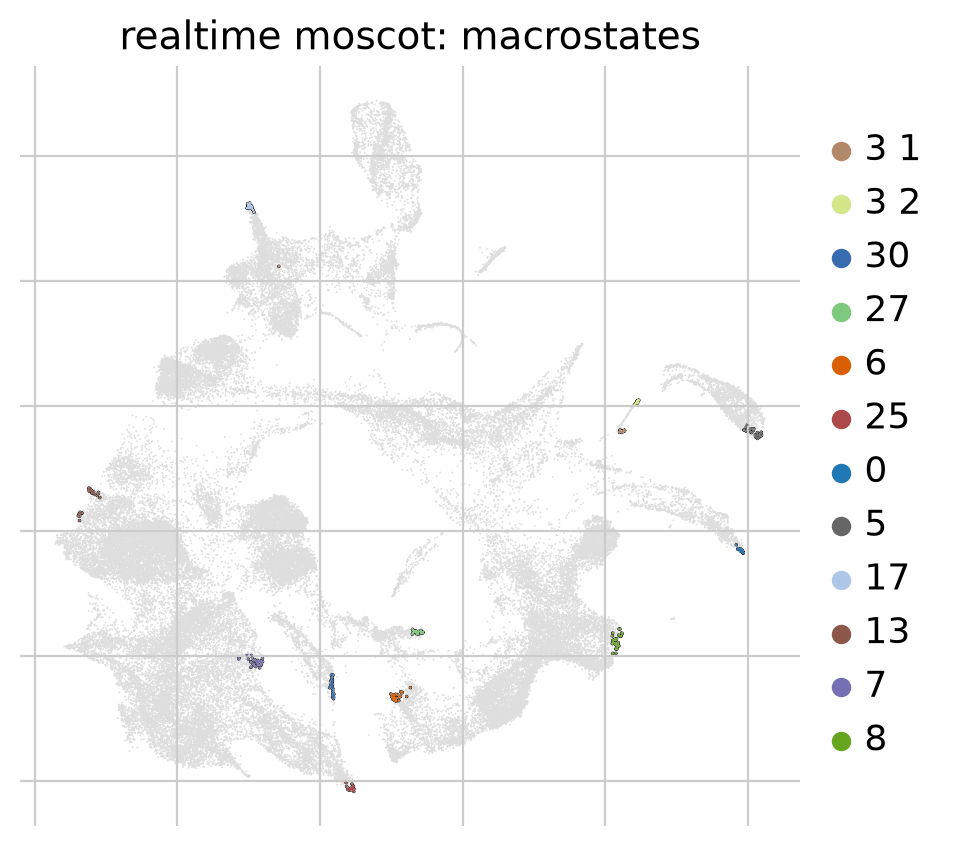

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_realtime_moscot_terminal.png


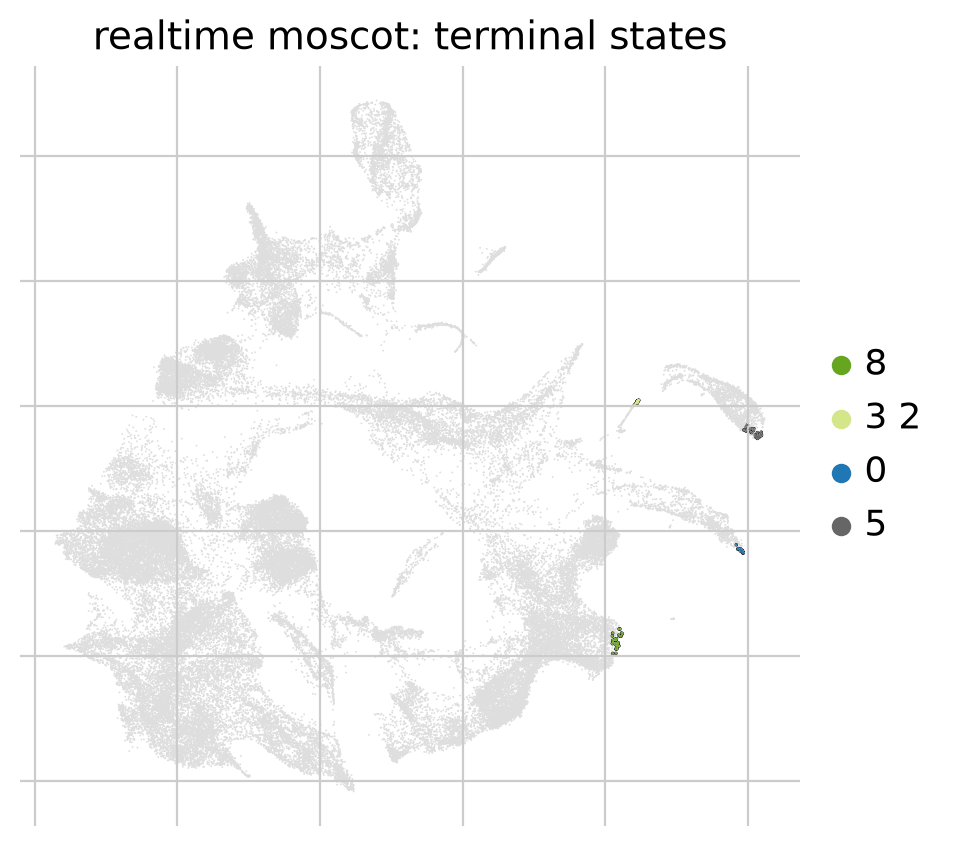

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_realtime_moscot_initial.png


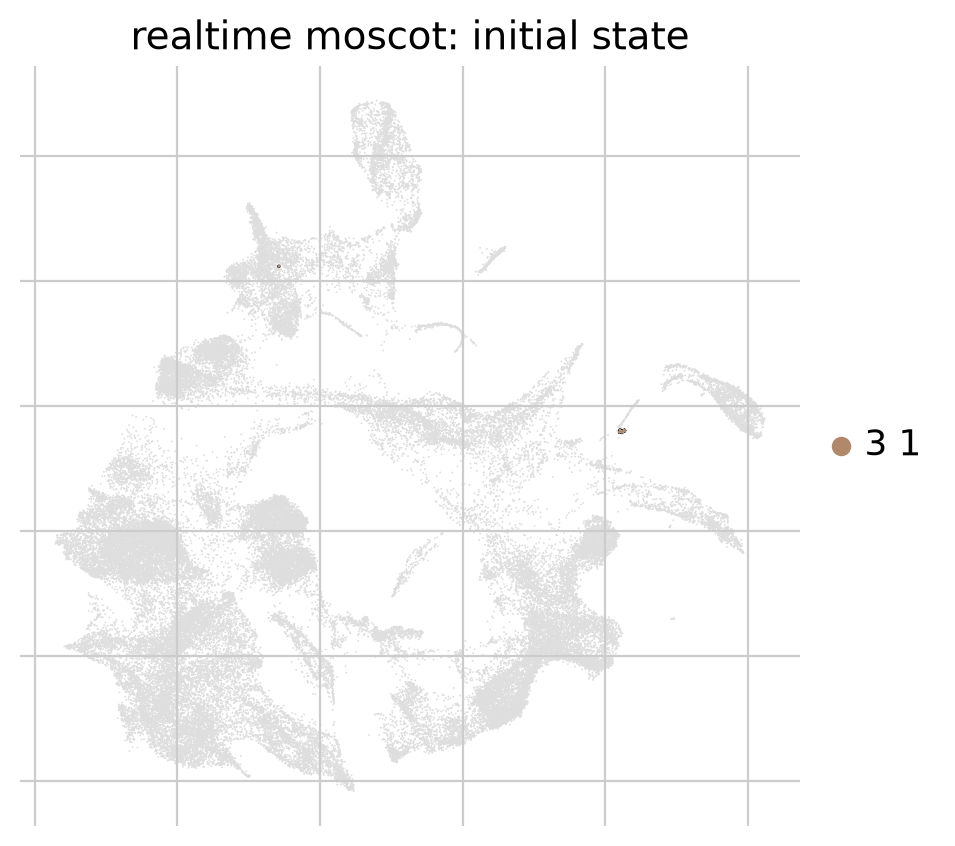

  wrote fate_realtime_moscot.csv, composition_*_realtime_moscot.csv, macrostates_realtime_moscot.csv
connectivity


Computing Schur decomposition


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:06)


Computing `12` macrostates


Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:02:01)


...

100%|██████████| 4/4 [00:07<00:00,  1.89s/]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:00:07)


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_connectivity_macrostates.png


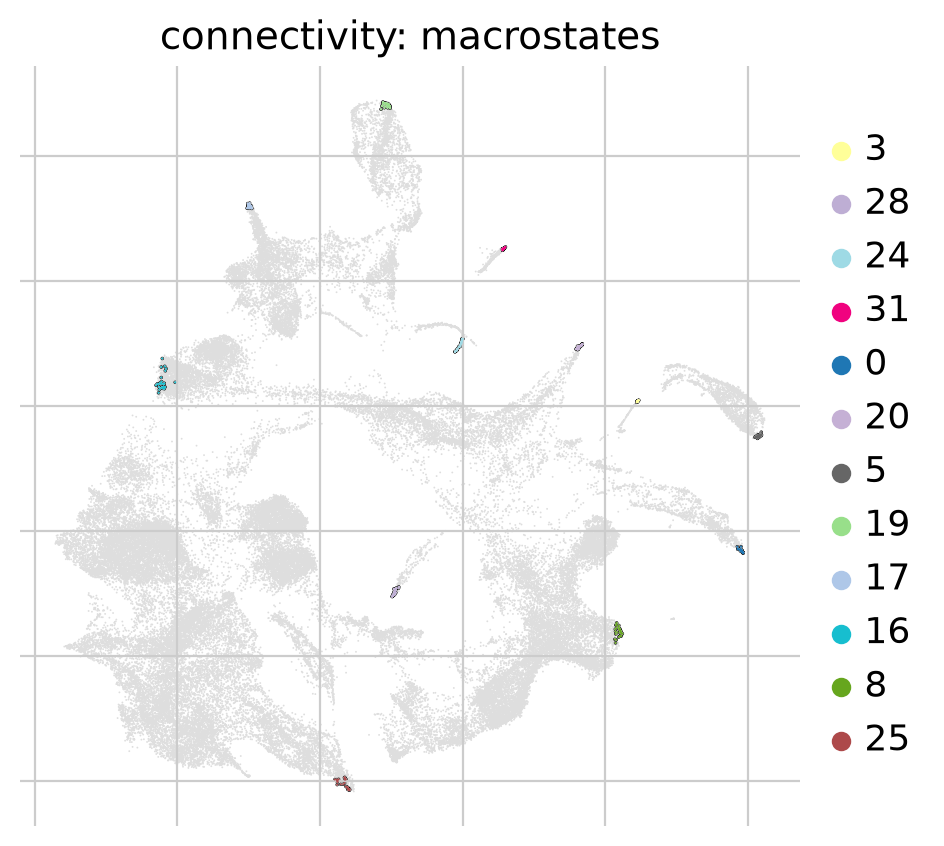

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_connectivity_terminal.png


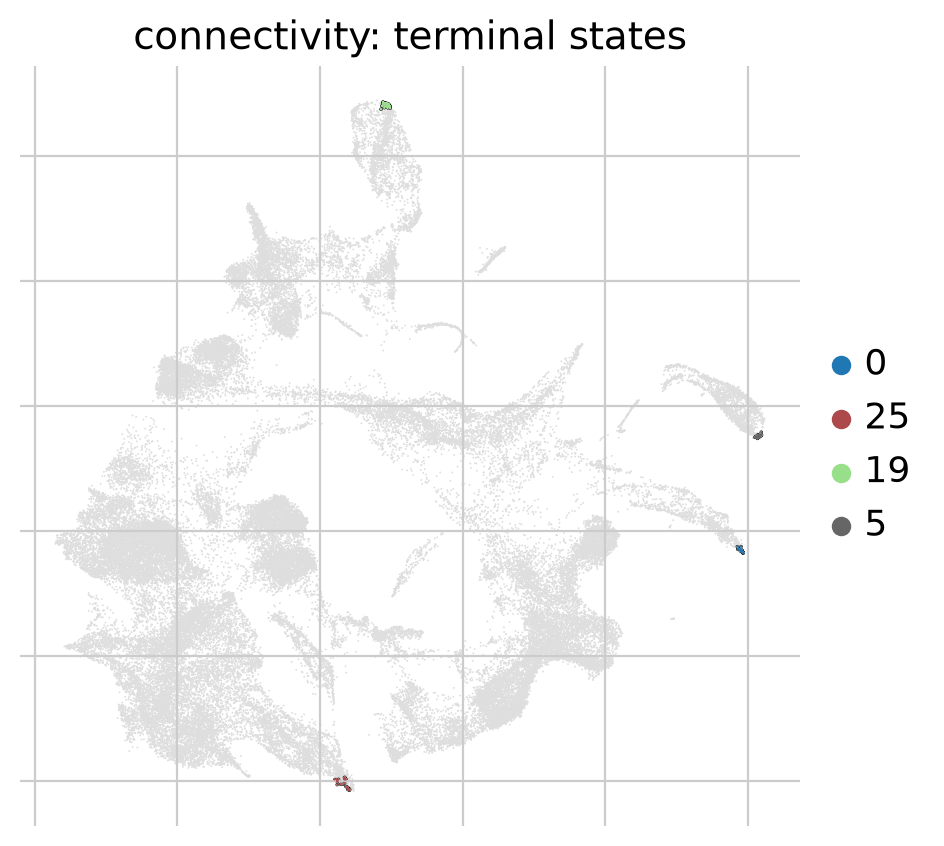

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_connectivity_initial.png


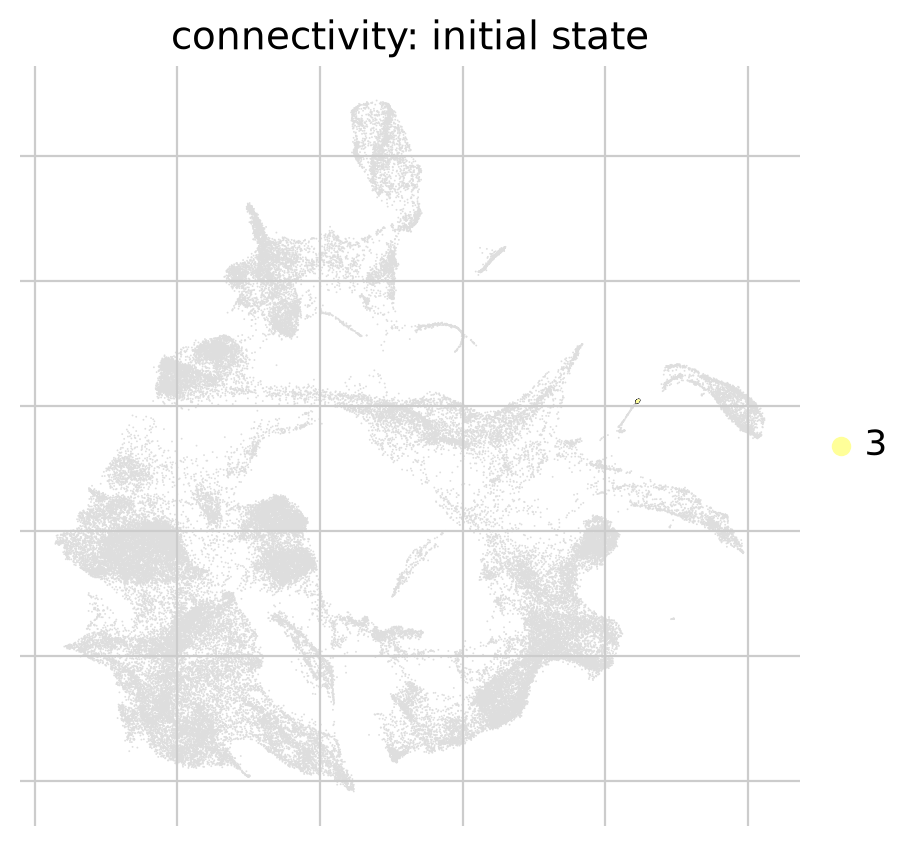

  wrote fate_connectivity.csv, composition_*_connectivity.csv, macrostates_connectivity.csv
vk0.8_ck0.2


Computing Schur decomposition


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:00:06)


Computing `12` macrostates


Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:01:56)


...

100%|██████████| 4/4 [00:28<00:00,  7.08s/]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:00:28)


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.8_ck0.2_macrostates.png


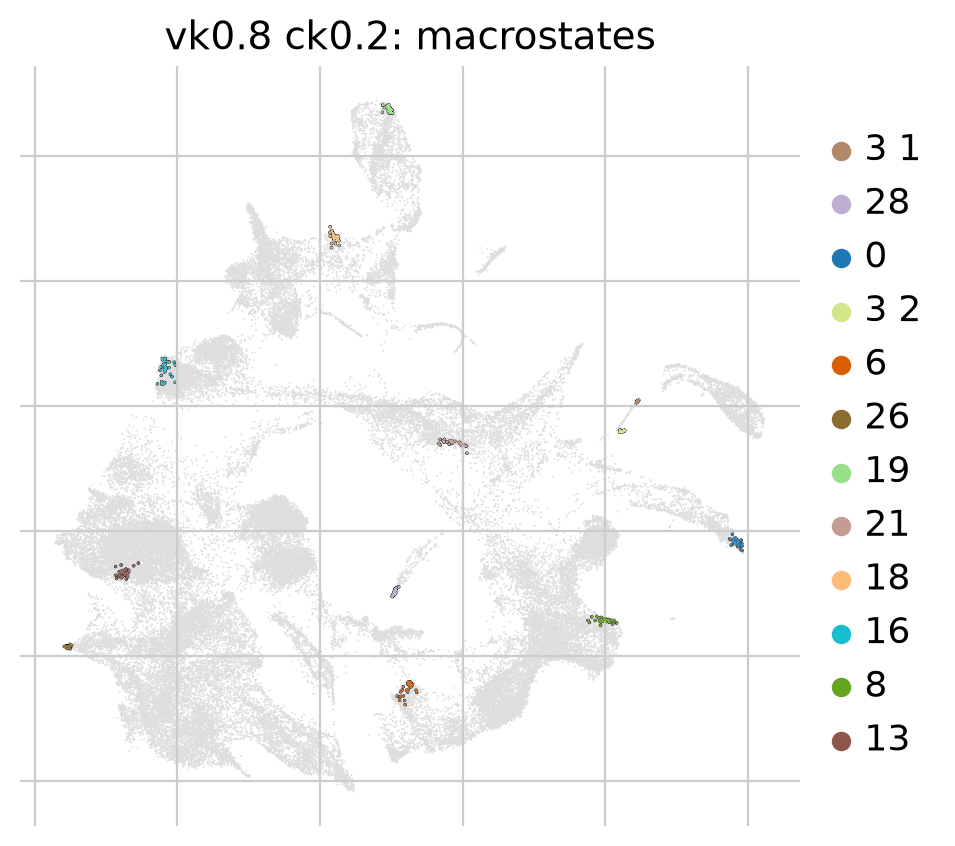

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.8_ck0.2_terminal.png


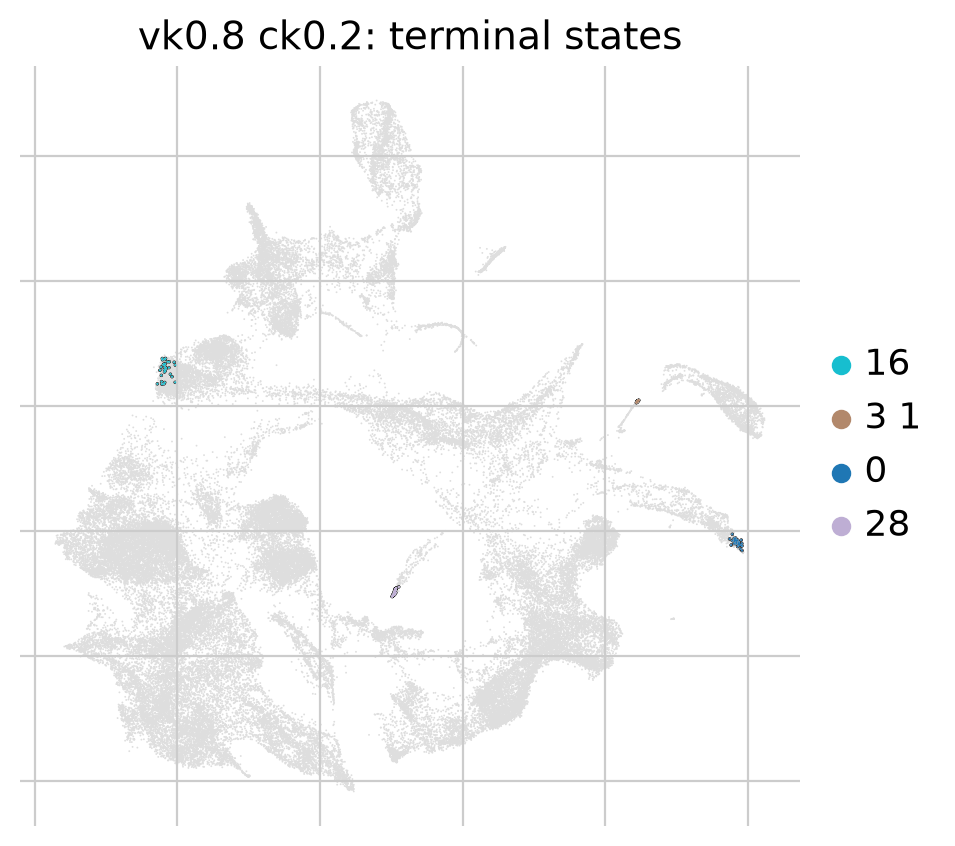

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.8_ck0.2_initial.png


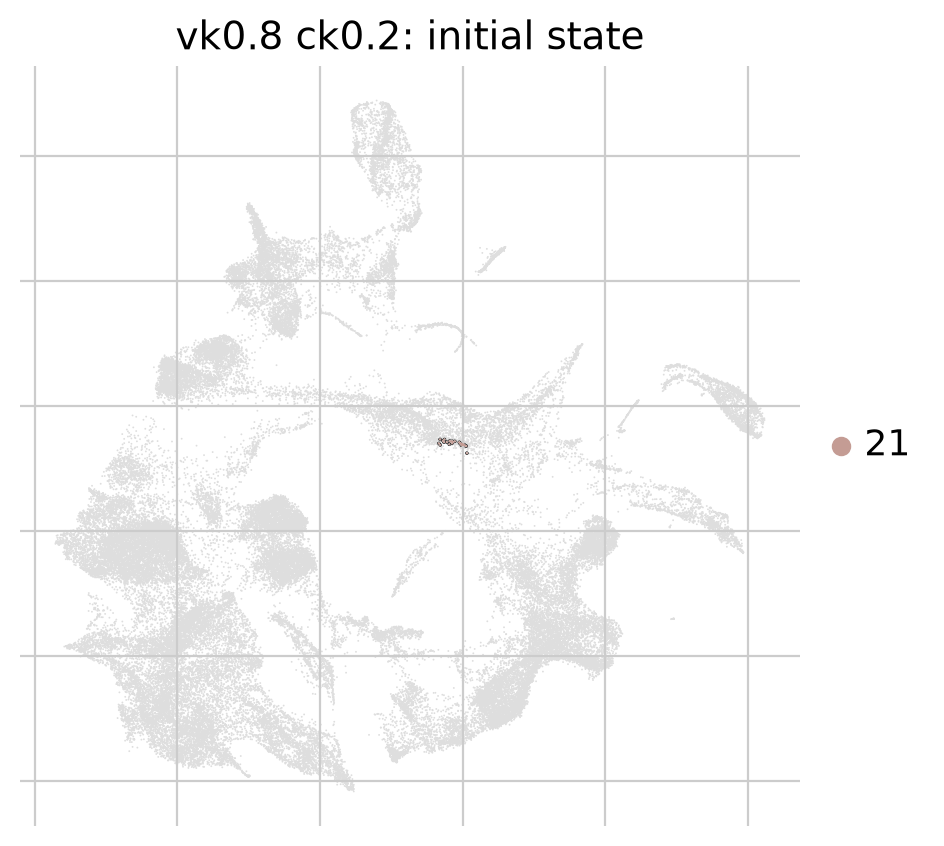

  wrote fate_vk0.8_ck0.2.csv, composition_*_vk0.8_ck0.2.csv, macrostates_vk0.8_ck0.2.csv
vk0.8_rtk0.2


Computing Schur decomposition


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:02:57)


Computing `12` macrostates


Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:23:44)


...

100%|██████████| 4/4 [06:56<00:00, 104.14s/]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:07:00)


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.8_rtk0.2_macrostates.png


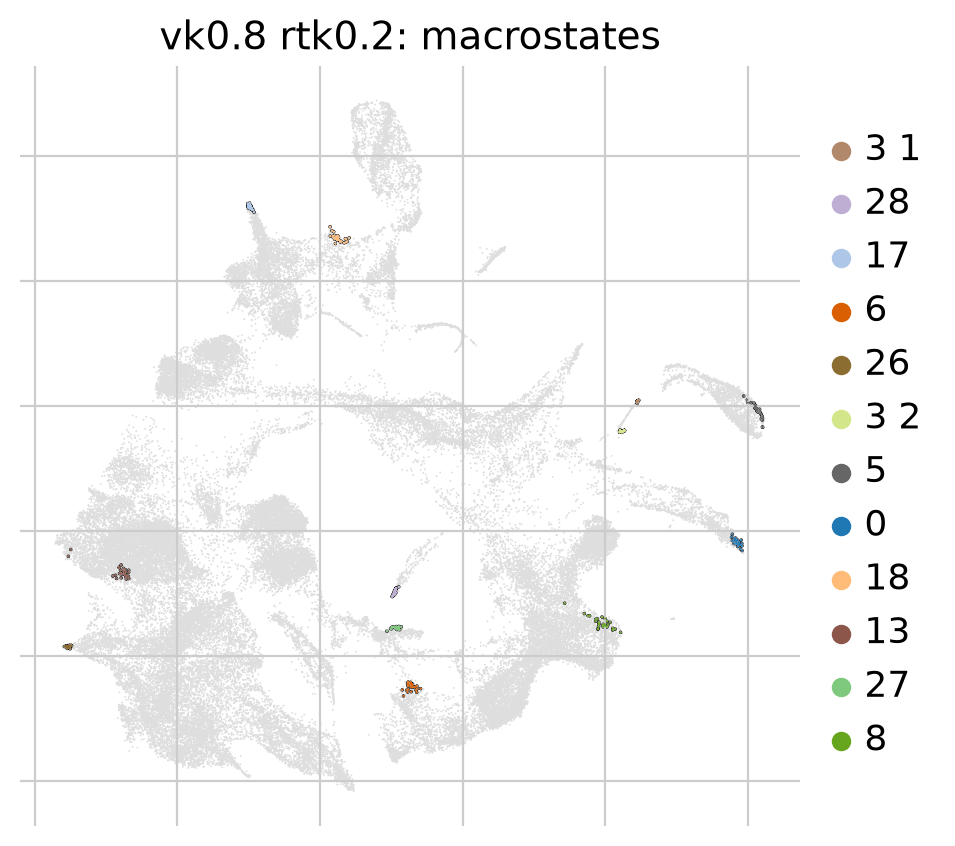

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.8_rtk0.2_terminal.png


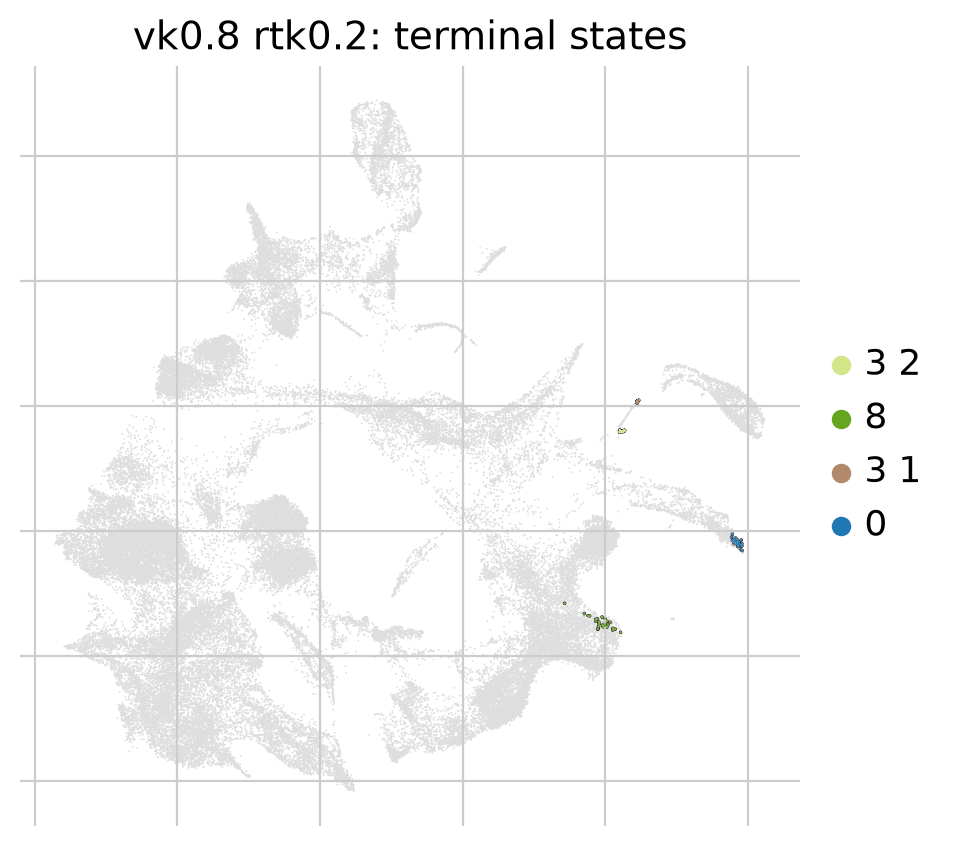

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.8_rtk0.2_initial.png


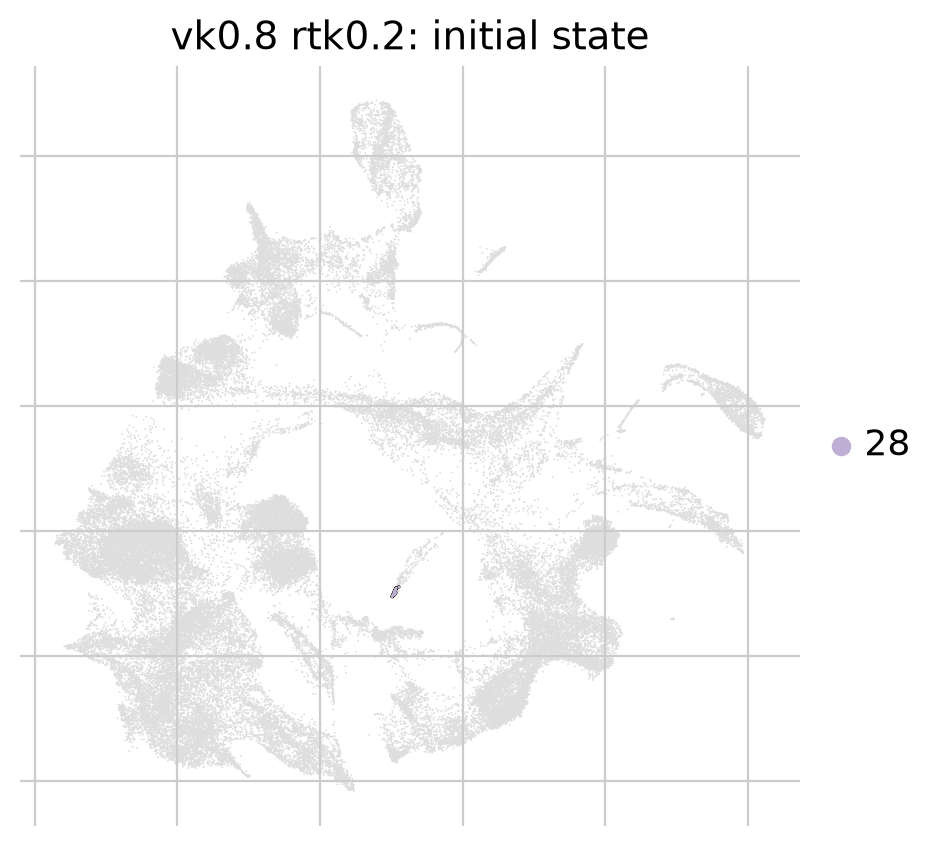

  wrote fate_vk0.8_rtk0.2.csv, composition_*_vk0.8_rtk0.2.csv, macrostates_vk0.8_rtk0.2.csv
vk0.5_rtk0.5


Computing Schur decomposition


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:02:50)


Computing `12` macrostates


Adding `.macrostates`
       `.macrostates_memberships`
       `.coarse_T`
       `.coarse_initial_distribution
       `.coarse_stationary_distribution`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:10:55)


...

100%|██████████| 4/4 [05:59<00:00, 89.92s/]

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:06:03)


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.5_rtk0.5_macrostates.png


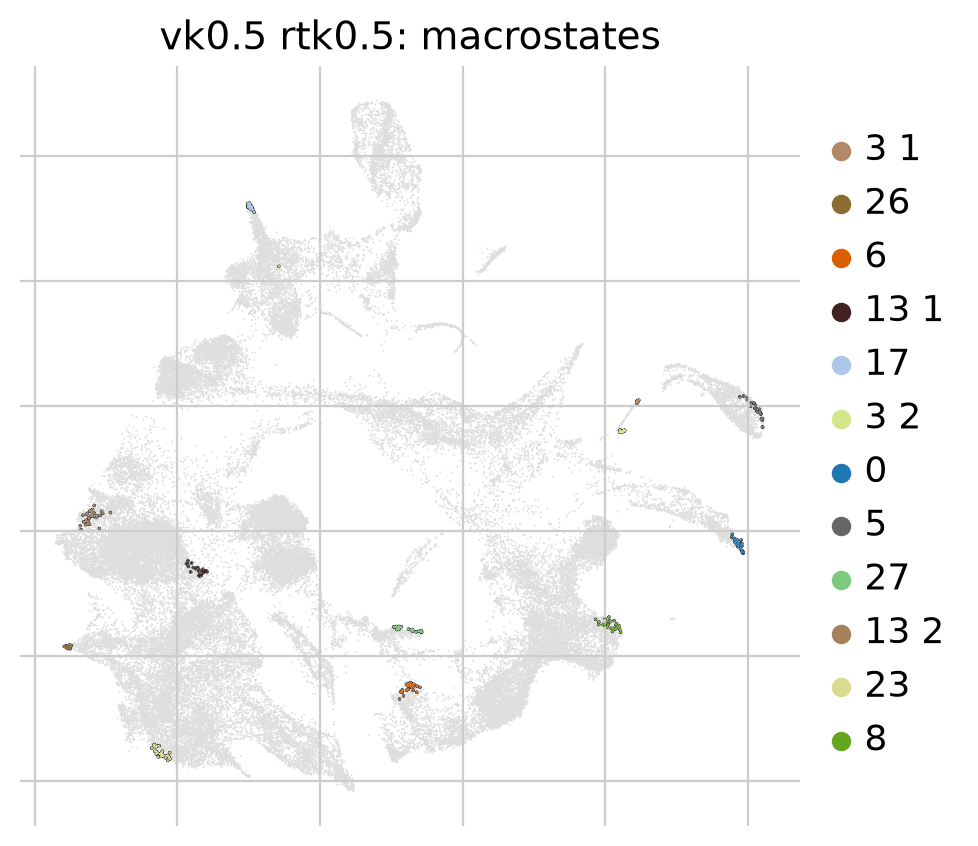

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.5_rtk0.5_terminal.png


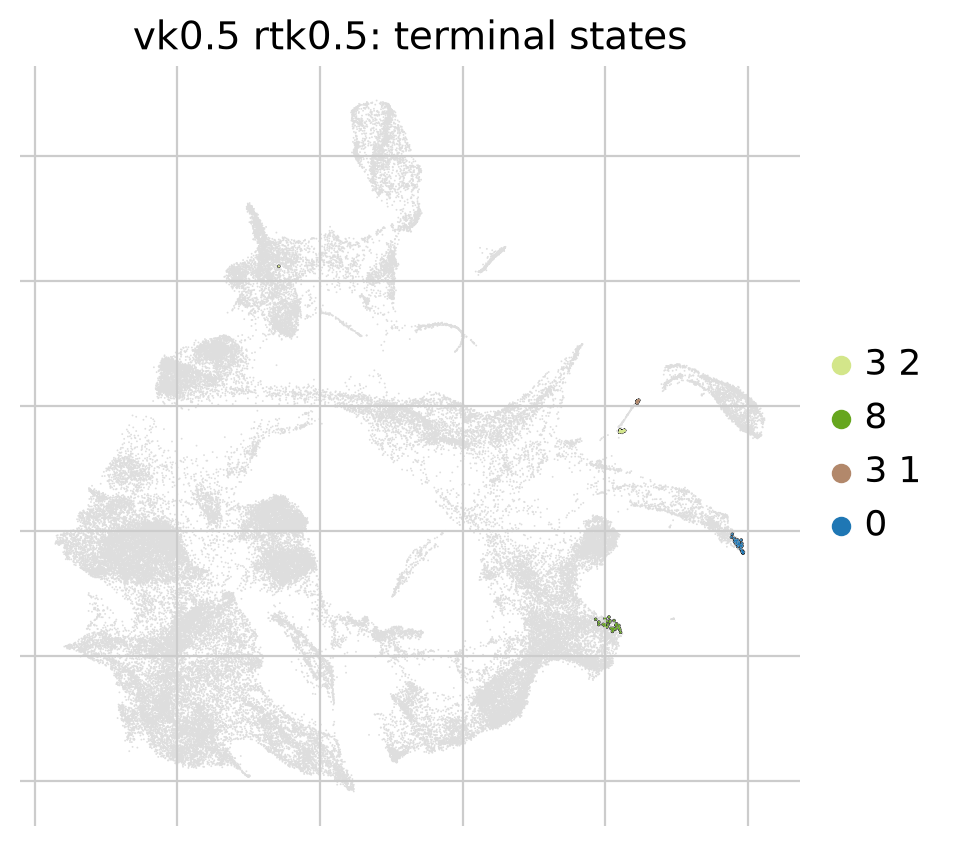

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.5_rtk0.5_initial.png


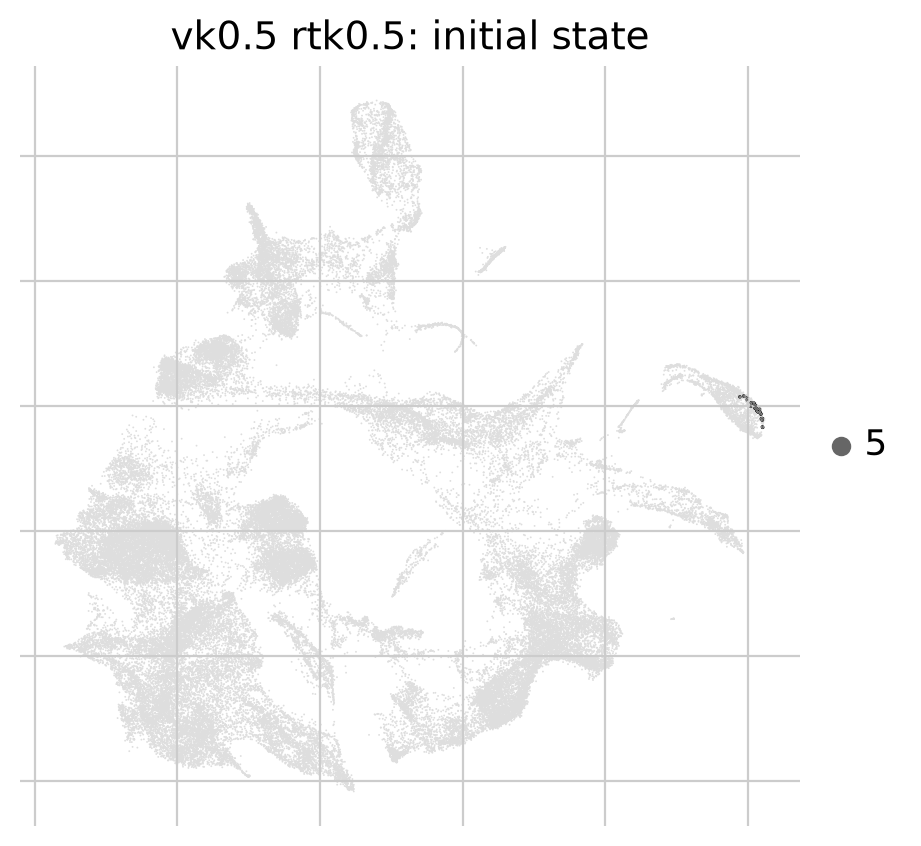

  wrote fate_vk0.5_rtk0.5.csv, composition_*_vk0.5_rtk0.5.csv, macrostates_vk0.5_rtk0.5.csv
vk0.2_rtk0.8


Computing Schur decomposition


When computing macrostates, choose a number of states NOT in `[np.int64(18)]`


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:03:36)


Computing `12` macrostates


...

Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:07:04)



[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 13 Broken Pipe: Likely while reading or writing to a socket
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.2_rtk0.8_macrostates.png


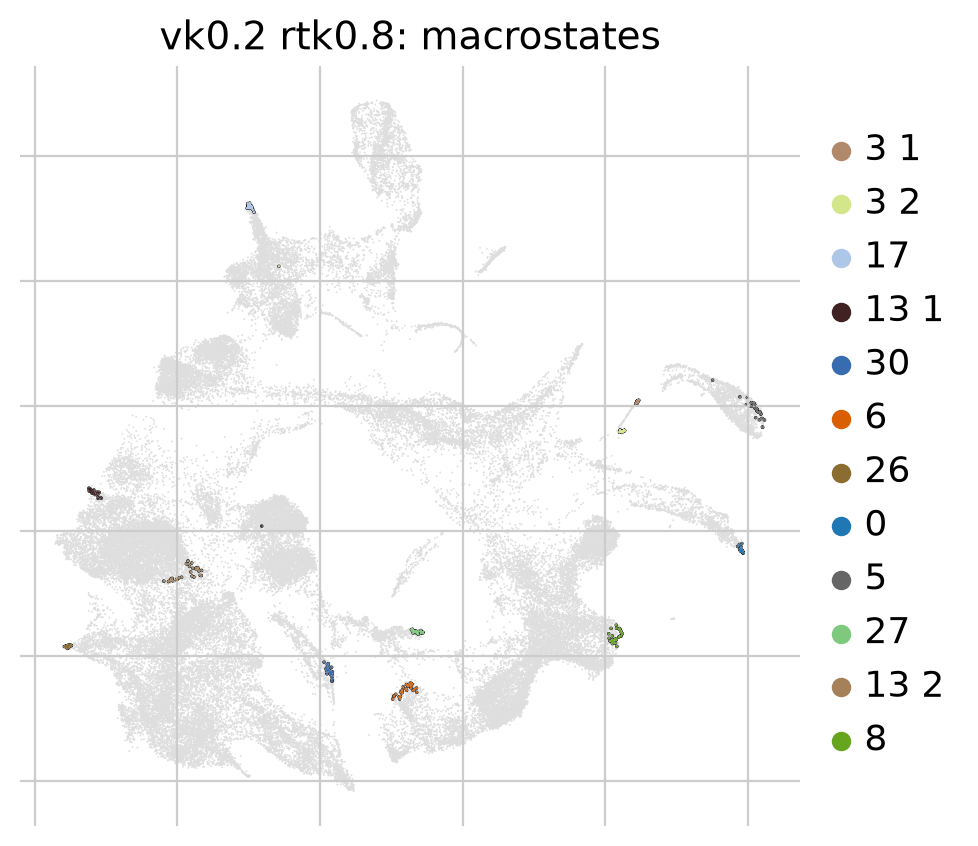

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.2_rtk0.8_terminal.png


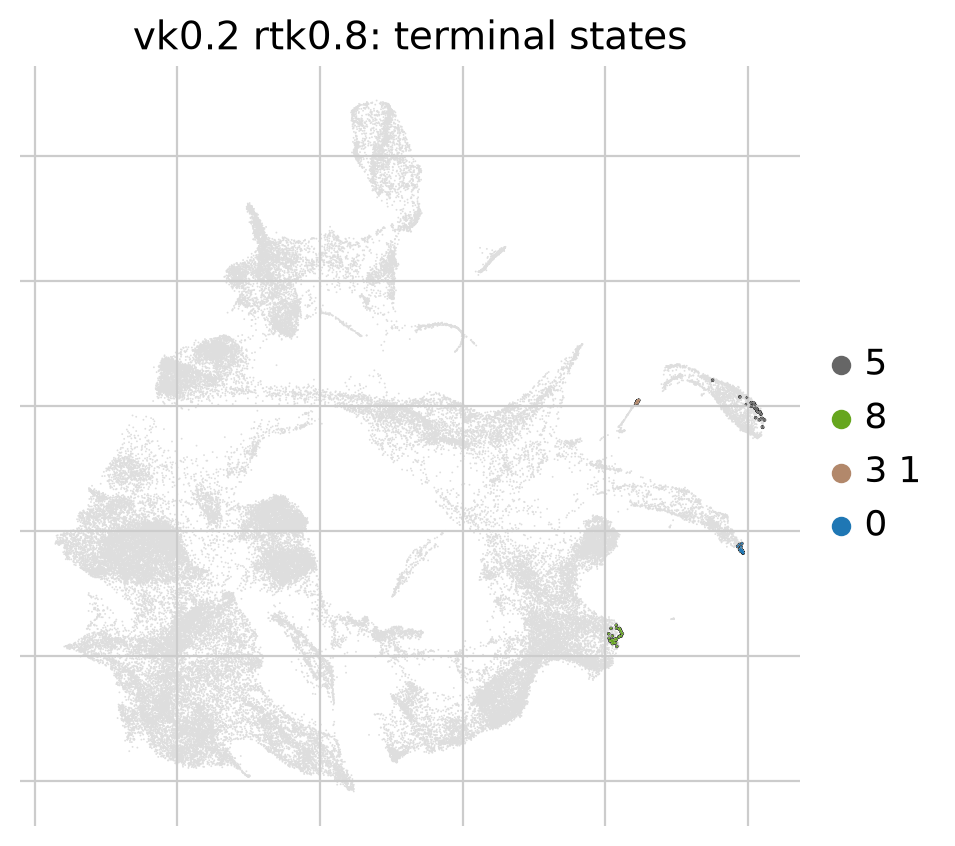

  wrote fate_vk0.2_rtk0.8.csv, composition_*_vk0.2_rtk0.8.csv, macrostates_vk0.2_rtk0.8.csv
vk0.6_rtk0.2_ck0.2


Computing Schur decomposition


When computing macrostates, choose a number of states NOT in `[np.int64(20)]`


Adding `adata.uns['eigendecomposition_fwd']`
       `.schur_vectors`
       `.schur_matrix`
       `.eigendecomposition`
    Finish (0:10:25)


Computing `12` macrostates


...


[0]PETSC ERROR: ------------------------------------------------------------------------
[0]PETSC ERROR: Caught signal number 13 Broken Pipe: Likely while reading or writing to a socket
[0]PETSC ERROR: Try option -start_in_debugger or -on_error_attach_debugger
[0]PETSC ERROR: or see https://petsc.org/release/faq/#valgrind and https://petsc.org/release/faq/
[0]PETSC ERROR: configure using --with-debugging=yes, recompile, link, and run 
[0]PETSC ERROR: to get more information on the crash.
Abort(59) on node 0 (rank 0 in comm 0): application called MPI_Abort(MPI_COMM_WORLD, 59) - process 0


Adding `adata.obsm['lineages_fwd']`
       `.fate_probabilities`
    Finish (0:04:02)


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.6_rtk0.2_ck0.2_macrostates.png


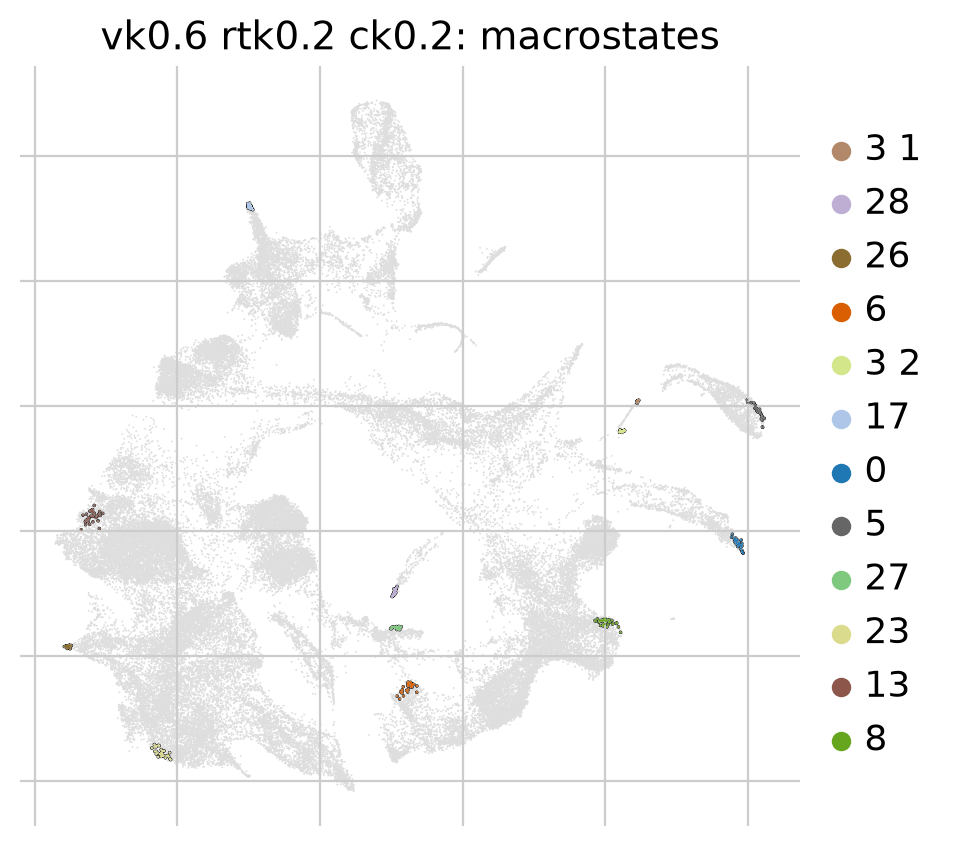

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(


/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.6_rtk0.2_ck0.2_terminal.png


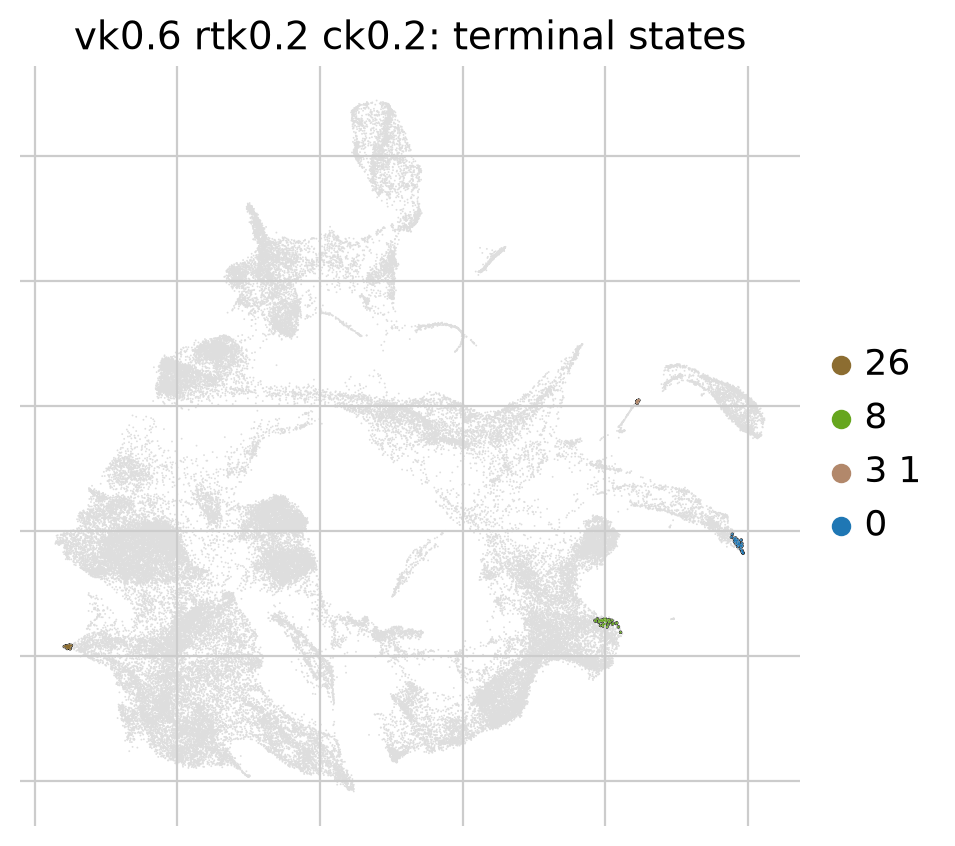

/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:656: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  smp = ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/scatter.py:694: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1400: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=bg_size, marker=".", c=bg_color, zorder=zord - 2, **kwargs)
/project/imoskowitz/yubin/envs/cellrank_traj/lib/python3.11/site-packages/scvelo/plotting/utils.py:1401: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  ax.scatter(x, y, s=gp_size, marker=".", c=gp_color, zorder=zord - 1, **kwargs)


saving figure to file /project/imoskowitz/yubin/Trajectory_inference/output_fig/07_cellrank/scvelo_vk0.6_rtk0.2_ck0.2_initial.png


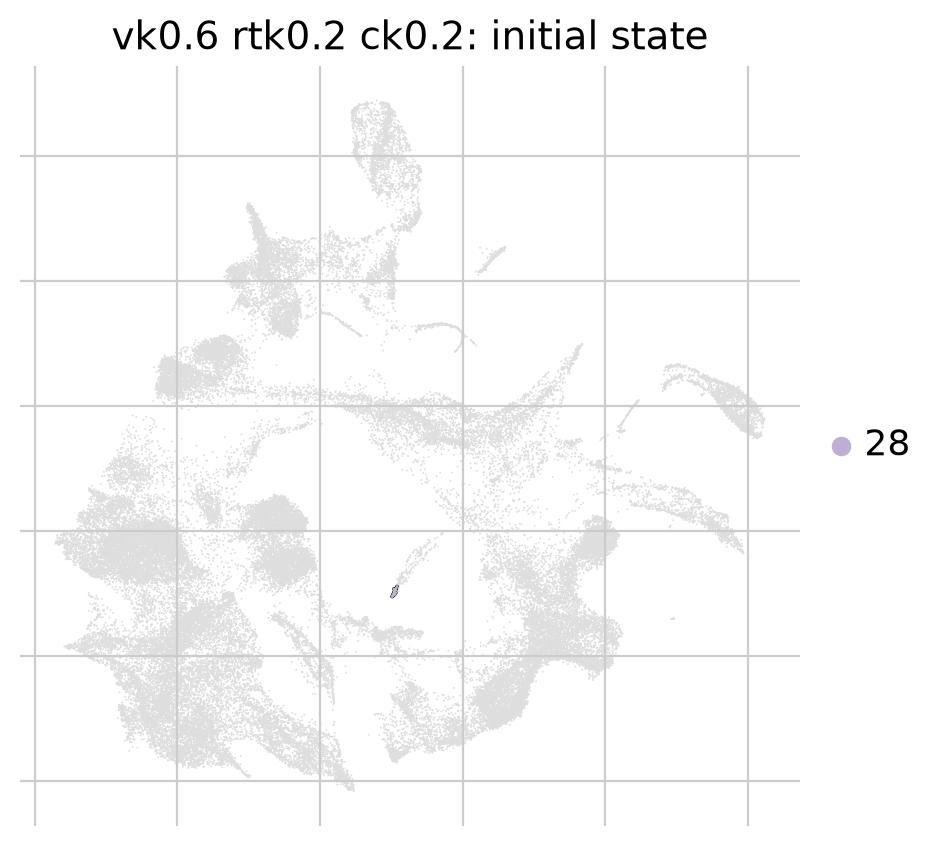

  wrote fate_vk0.6_rtk0.2_ck0.2.csv, composition_*_vk0.6_rtk0.2_ck0.2.csv, macrostates_vk0.6_rtk0.2_ck0.2.csv

7/8 kernels succeeded


In [12]:
def run_estimator(name, kernel, n_states=N_STATES, cluster_key="leiden_joint"):
    """GPCCA on one kernel: macrostates, terminal + initial states, fate probabilities."""
    print("=" * 70, f"\n{name}\n", "=" * 70, flush=True)
    g = cr.estimators.GPCCA(kernel)
    g.compute_schur(n_components=n_states + 8, method="krylov")
    g.compute_macrostates(n_states=n_states, cluster_key=cluster_key)
    # method="stability" is the default; its 0.96 self-transition threshold
    # selected no macrostate at all on this data and raised, losing all eight
    # runs at once (job 61837986). top_n pins the count instead, which also
    # keeps the runs comparable.
    g.predict_terminal_states(method="top_n", n_states=N_TERMINAL)
    try:
        g.predict_initial_states(n_states=1)
        init = list(g.initial_states.cat.categories)
    except Exception as e:                     # some kernels give no clean initial state
        print(f"  initial-state prediction failed: {e}")
        init = []
    term = list(g.terminal_states.cat.categories)
    print(f"  terminal states: {term}")
    print(f"  initial states : {init}")

    # which stage does each macrostate sit in?
    ms = g.macrostates
    keep = ~ms.isna()
    comp = (pd.crosstab(ms[keep], adata.obs.loc[keep, "age"], normalize="index") * 100).round(1)
    print("\n  macrostate composition by stage (%):")
    print(comp.to_string())
    # dissection is confounded with stage (METHODS.md 10b: All -> Head -> regions),
    # so report tissue too: a state that looks stage-specific may be region-specific.
    comp_t = None
    if "tissue" in adata.obs:
        comp_t = (pd.crosstab(ms[keep], adata.obs.loc[keep, "tissue"], normalize="index") * 100).round(1)
        print("\n  macrostate composition by tissue (%):")
        print(comp_t.to_string())

    g.compute_fate_probabilities()
    fate = pd.DataFrame(np.asarray(g.fate_probabilities),
                        columns=list(g.fate_probabilities.names), index=adata.obs_names)

    g.plot_macrostates(which="all", basis=BASIS, legend_loc="right",
                       title=f"{name}: macrostates", save=f"{name}_macrostates.png")
    g.plot_macrostates(which="terminal", basis=BASIS, legend_loc="right",
                       title=f"{name}: terminal states", save=f"{name}_terminal.png")
    if init:
        g.plot_macrostates(which="initial", basis=BASIS, legend_loc="right",
                           title=f"{name}: initial state", save=f"{name}_initial.png")
    # write inside the function so a later failure cannot discard earlier results
    fate.to_csv(res_dir + f"fate_{name}.csv")
    comp.to_csv(res_dir + f"composition_stage_{name}.csv")
    if comp_t is not None:
        comp_t.to_csv(res_dir + f"composition_tissue_{name}.csv")
    ms.to_frame("macrostate").to_csv(res_dir + f"macrostates_{name}.csv")
    print(f"  wrote fate_{name}.csv, composition_*_{name}.csv, macrostates_{name}.csv")

    return {"name": name, "terminal": term, "initial": init, "composition": comp,
            "composition_tissue": comp_t, "fate": fate, "macrostates": ms}


import traceback

results = {}
for name, kern in KERNELS.items():
    try:
        results[name] = run_estimator(name, kern)
    except Exception as e:
        # print the traceback: job 61837986 swallowed eight of these and left only an
        # empty heatmap behind, so finding the cause cost an entire extra run.
        print(f"!! {name} FAILED: {type(e).__name__}: {e}", flush=True)
        traceback.print_exc()
        results[name] = {"name": name, "error": f"{type(e).__name__}: {e}"}

n_ok = sum("error" not in r for r in results.values())
print(f"\n{n_ok}/{len(KERNELS)} kernels succeeded", flush=True)
if n_ok == 0:
    raise RuntimeError("every kernel failed - see the tracebacks above; the "
                       "comparison cells below would all render empty")

## Compare the runs

In [13]:
rows = []
for name, r in results.items():
    if "error" in r:
        rows.append({"kernel": name, "status": "FAILED", "n_terminal": None,
                     "initial_state": r["error"][:40], "initial_stage": None})
        continue
    init_stage = None
    if r["initial"]:
        ms = r["macrostates"]
        sel = ms.isin(r["initial"])
        if sel.any():
            init_stage = (adata.obs.loc[sel.values, "age"].value_counts(normalize=True)
                          .idxmax())
    rows.append({"kernel": name, "status": "ok", "n_terminal": len(r["terminal"]),
                 "initial_state": ", ".join(r["initial"]) if r["initial"] else "none",
                 "initial_stage": init_stage})
overview = pd.DataFrame(rows)
print(overview.to_string(index=False))
overview.to_csv(res_dir + "kernel_overview.csv", index=False)

            kernel status  n_terminal                            initial_state initial_stage
          velocity FAILED         NaN ValueError: `60762` value(s) do not sum           None
   realtime_moscot     ok         4.0                                      3_1         e10.0
      connectivity     ok         4.0                                        3         e10.0
       vk0.8_ck0.2     ok         4.0                                       21          e7.0
      vk0.8_rtk0.2     ok         4.0                                       28          e8.0
      vk0.5_rtk0.5     ok         4.0                                        5         e10.0
      vk0.2_rtk0.8     ok         4.0                                     none          None
vk0.6_rtk0.2_ck0.2     ok         4.0                                       28          e8.0


mean correlation of fate probabilities over shared terminal states:
                    realtime_moscot  connectivity  vk0.8_ck0.2  vk0.8_rtk0.2  vk0.5_rtk0.5  vk0.2_rtk0.8  vk0.6_rtk0.2_ck0.2
realtime_moscot               1.000         0.932        0.529         0.489         0.499         0.972               0.680
connectivity                  0.932         1.000        0.477         0.885         0.891         0.921               0.821
vk0.8_ck0.2                   0.529         0.477        1.000         0.442         0.439         0.594               0.552
vk0.8_rtk0.2                  0.489         0.885        0.442         1.000         0.993         0.780               0.706
vk0.5_rtk0.5                  0.499         0.891        0.439         0.993         1.000         0.792               0.719
vk0.2_rtk0.8                  0.972         0.921        0.594         0.780         0.792         1.000               0.799
vk0.6_rtk0.2_ck0.2            0.680         0.821        

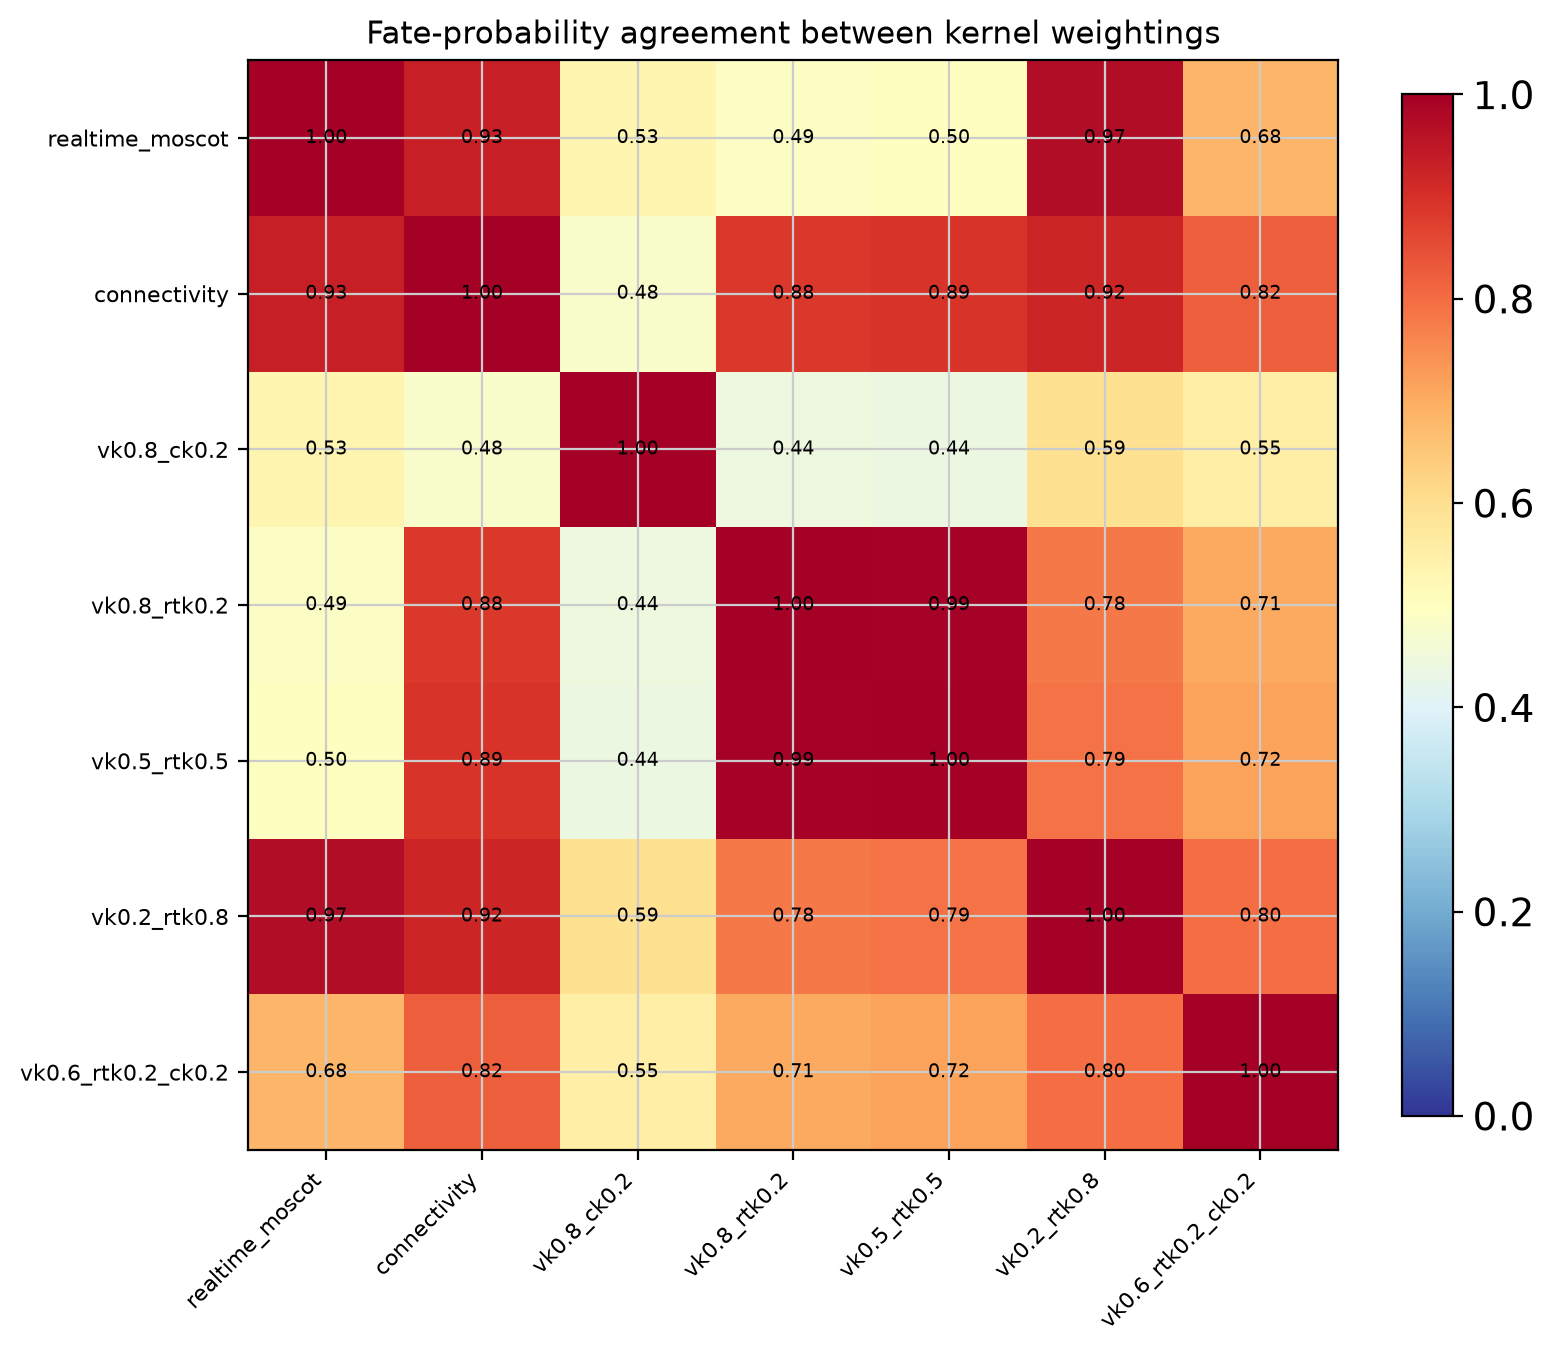

In [14]:
# do the weightings agree on fate? correlate fate probabilities between runs
ok = {n: r for n, r in results.items() if "error" not in r}
names = list(ok)
agree = pd.DataFrame(index=names, columns=names, dtype=float)
for a in names:
    for b in names:
        fa, fb = ok[a]["fate"], ok[b]["fate"]
        shared = [c for c in fa.columns if c in fb.columns]
        if not shared:
            agree.loc[a, b] = np.nan
            continue
        agree.loc[a, b] = float(np.mean([
            np.corrcoef(fa[c].values, fb[c].values)[0, 1] for c in shared
        ]))
print("mean correlation of fate probabilities over shared terminal states:")
print(agree.astype(float).round(3).to_string())
agree.to_csv(res_dir + "fate_probability_agreement.csv")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(agree.astype(float).values, cmap="RdYlBu_r", vmin=0, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(names))); ax.set_yticklabels(names, fontsize=8)
for i in range(len(names)):
    for j in range(len(names)):
        v = agree.astype(float).values[i, j]
        if not np.isnan(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7)
ax.set_title("Fate-probability agreement between kernel weightings", fontsize=11)
plt.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
fig.savefig(fig_cr + "kernel_agreement.png", dpi=200, bbox_inches="tight")

In [15]:
# terminal-state overlap: do different weightings nominate the same clusters?
term_sets = {n: set(r["terminal"]) for n, r in ok.items()}
print("terminal states per run:")
for n, s in term_sets.items():
    print(f"  {n:22s} {sorted(s)}")
allt = sorted(set().union(*term_sets.values())) if term_sets else []
tab = pd.DataFrame({n: [t in s for t in allt] for n, s in term_sets.items()}, index=allt)
print("\nterminal state x run (True = nominated):")
print(tab.to_string())
tab.to_csv(res_dir + "terminal_state_overlap.csv")

terminal states per run:
  realtime_moscot        [np.str_('0'), np.str_('3_2'), np.str_('5'), np.str_('8')]
  connectivity           [np.str_('0'), np.str_('19'), np.str_('25'), np.str_('5')]
  vk0.8_ck0.2            [np.str_('0'), np.str_('16'), np.str_('28'), np.str_('3_1')]
  vk0.8_rtk0.2           [np.str_('0'), np.str_('3_1'), np.str_('3_2'), np.str_('8')]
  vk0.5_rtk0.5           [np.str_('0'), np.str_('3_1'), np.str_('3_2'), np.str_('8')]
  vk0.2_rtk0.8           [np.str_('0'), np.str_('3_1'), np.str_('5'), np.str_('8')]
  vk0.6_rtk0.2_ck0.2     [np.str_('0'), np.str_('26'), np.str_('3_1'), np.str_('8')]

terminal state x run (True = nominated):
     realtime_moscot  connectivity  vk0.8_ck0.2  vk0.8_rtk0.2  vk0.5_rtk0.5  vk0.2_rtk0.8  vk0.6_rtk0.2_ck0.2
0               True          True         True          True          True          True                True
16             False         False         True         False         False         False               False
19      

## Save

In [16]:
import resource
print(f"peak RSS: {resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1e6:.1f} GB")

for name, r in results.items():
    if "error" in r:
        continue
    adata.obs[f"macro_{name}"] = r["macrostates"]   # fate_*.csv written in run_estimator

# compute_fate_probabilities leaves cellrank Lineage objects in obsm, which
# anndata cannot serialise; column names are preserved in the fate_*.csv files.
for k in [k for k in adata.obsm if type(adata.obsm[k]).__name__ in ("Lineage", "LineageView")]:
    print(f"  obsm['{k}']: {type(adata.obsm[k]).__name__} -> ndarray")
    adata.obsm[k] = np.asarray(adata.obsm[k])

adata.write_h5ad(base + "data/devbrain_cellrank.h5ad", compression="gzip")
print("wrote data/devbrain_cellrank.h5ad")

peak RSS: 37.5 GB
  obsm['macrostates_fwd_memberships']: Lineage -> ndarray
  obsm['term_states_fwd_memberships']: Lineage -> ndarray
  obsm['init_states_fwd_memberships']: Lineage -> ndarray
  obsm['lineages_fwd']: Lineage -> ndarray


wrote data/devbrain_cellrank.h5ad
